# How accurate are the NBP's inflation forecasts?

I compare the inflation forecasts in the National Bank of Poland's Inflation Reports (2008–2025) with actual CPI inflation from GUS (Statistics Office). Then I build three simple models of my own and test whether the NBP really beats them.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

df = pd.read_csv("nbp_forecasts.csv")
cpi = pd.read_csv("gus_annual_cpi.csv").set_index("year")["cpi"]
drivers = pd.read_csv("inflation_drivers.csv").set_index("year")
data = drivers.join(cpi)

df["actual_cpi"] = pd.to_numeric(df["actual_cpi"], errors="coerce")
df["nbp_error"] = df["actual_cpi"] - df["forecast_cpi"]
done = df.dropna(subset=["actual_cpi"]).copy()
done.head()

,round,round_year,round_month,target_year,horizon_years,forecast_cpi,actual_cpi,error_actual_minus_forecast,nbp_error
0,2008-06,2008,6,2008,0,4.3,4.2,-0.1,-0.1
1,2008-06,2008,6,2009,1,4.3,3.5,-0.8,-0.8
2,2008-06,2008,6,2010,2,3.1,2.6,-0.5,-0.5
3,2008-10,2008,10,2008,0,4.3,4.2,-0.1,-0.1
4,2008-10,2008,10,2009,1,4.7,3.5,-1.2,-1.2


## 1. How wrong is the NBP?

In [2]:
done.groupby("horizon_years")["nbp_error"].agg(
    avg_error="mean",
    avg_size_of_the_miss=lambda e: e.abs().mean(),
    n="count",
).round(2)

,avg_error,avg_size_of_the_miss,n
horizon_years,,,
0,0.07,0.39,52
1,0.34,1.92,49
2,1.01,2.39,46
3,0.10,0.10,1


Is the average error really different from zero, or just luck? A p-value below 0.05 would mean a real bias. Newey-West errors are used because forecasts made close together miss in similar ways.

In [3]:
for h in [0, 1, 2]:
    e = done.loc[done["horizon_years"] == h, "nbp_error"].reset_index(drop=True)
    result = sm.OLS(e, np.ones(len(e))).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    print(f"horizon {h}: average error {result.params.iloc[0]:+.2f}, p-value {result.pvalues.iloc[0]:.2f}")

horizon 0: average error +0.07, p-value 0.56
horizon 1: average error +0.34, p-value 0.63
horizon 2: average error +1.01, p-value 0.32


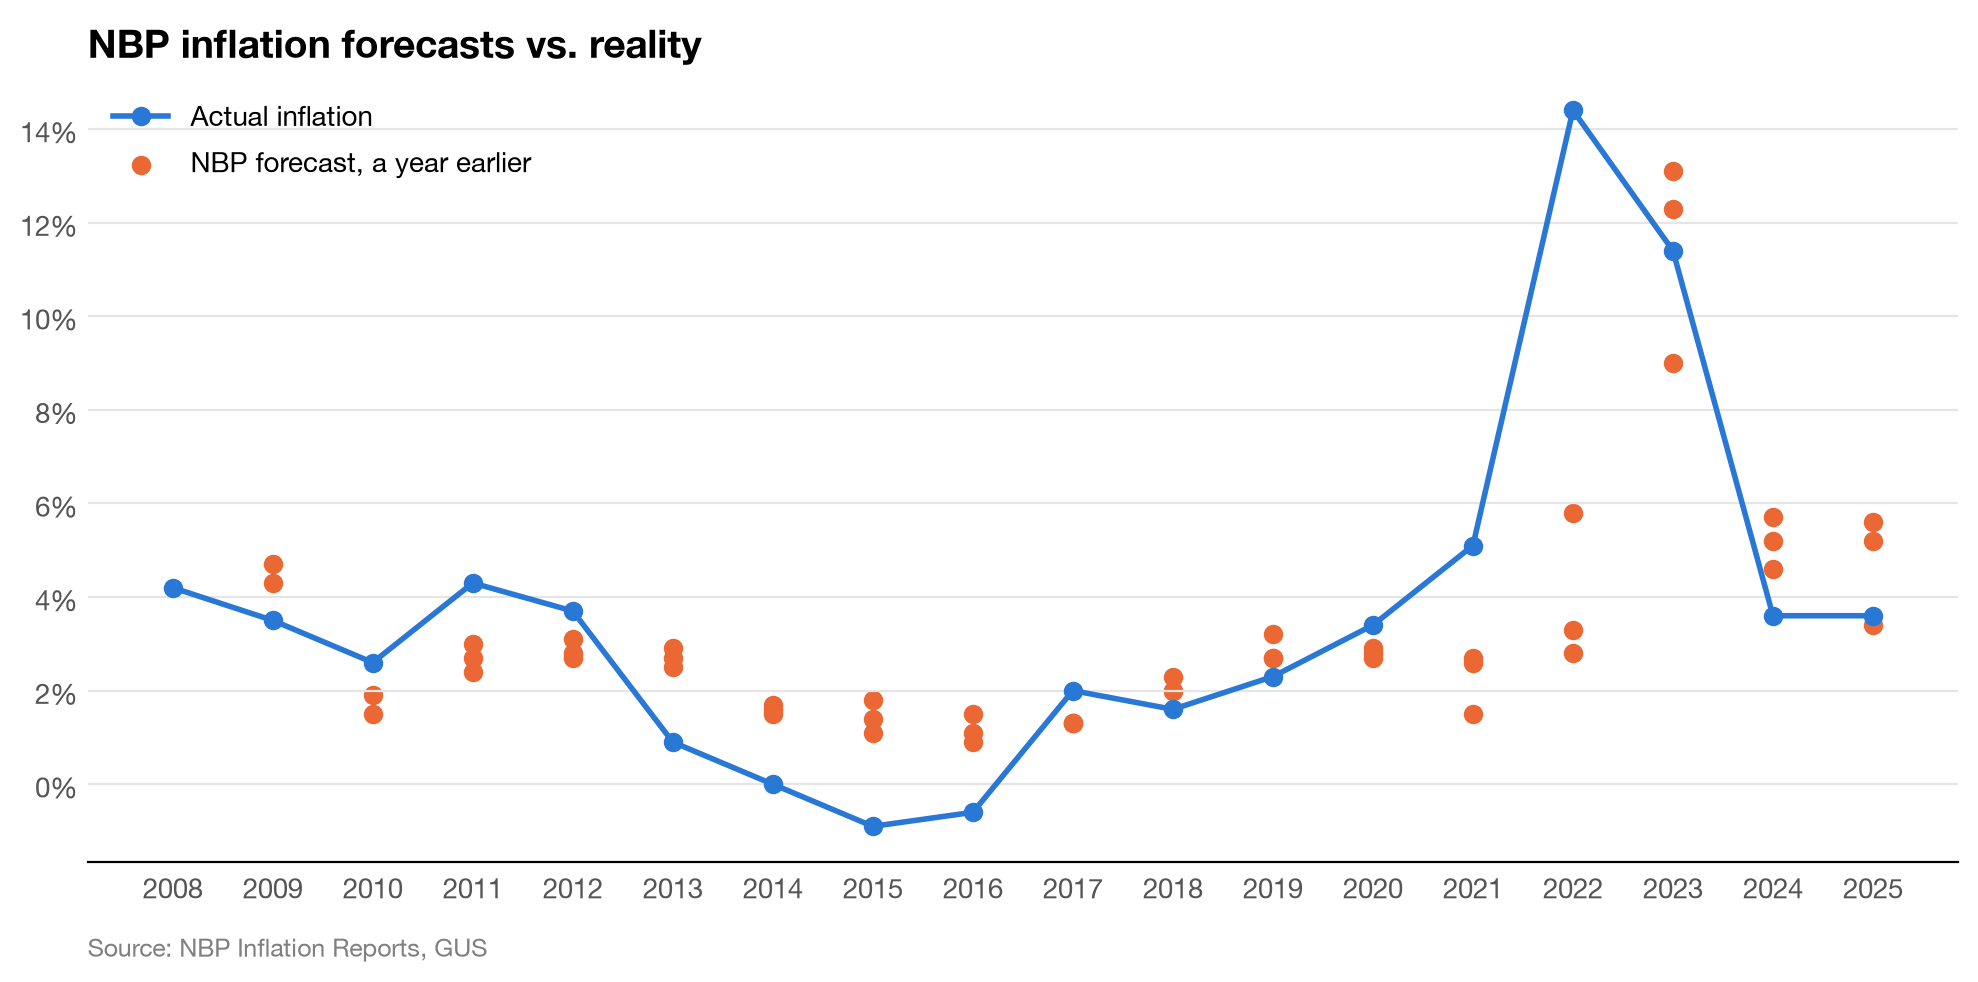

In [4]:
%config InlineBackend.figure_format = "retina"
plt.rcParams["font.family"] = "Helvetica Neue"

h1 = done[done["horizon_years"] == 1]
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(cpi.loc[2008:].index, cpi.loc[2008:].values, color="#2a78d6", lw=2, marker="o", label="Actual inflation")
ax.scatter(h1["target_year"], h1["forecast_cpi"], color="#eb6834", label="NBP forecast, a year earlier")

ax.set_title("NBP inflation forecasts vs. reality", loc="left", fontsize=14, fontweight="bold")
ax.set_xticks(cpi.loc[2008:].index)
ax.yaxis.set_major_formatter(lambda value, position: f"{value:.0f}%")
ax.grid(axis="y", color="#e5e5e5")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(frameon=False)
ax.tick_params(length=0, colors="#555555")
ax.text(0, -0.12, "Source: NBP Inflation Reports, GUS", transform=ax.transAxes, fontsize=9, color="gray")

plt.tight_layout()
plt.show()

### What this shows

- The further ahead the NBP looks, the bigger the miss: about 0.4 percentage points for the current year, 1.9 percentage points one year ahead and 2.4 percentage points two years ahead.
- On average their predictions do not lean too high or too low.
- That average hides big swings. It overestimated inflation after the 2008 crisis and in 2015–16, and badly underestimated it in 2021–2023.

## 2. Can a simple model do better?

Three models, each only allowed to use data that existed when the NBP made its forecast:

- Naive guess: inflation stays at last year's level.
- Classic AR(1): next year = a + b × this year, using past inflation only.
- Multi-variable: also uses wage growth, the oil price in złoty and the EUR/PLN rate.

In [5]:
def naive_forecast(round_year, target_year):
    return cpi[round_year - 1]


def ar1_forecast(round_year, target_year):
    history = cpi.loc[:round_year - 1]
    b, a = np.polyfit(history.values[:-1], history.values[1:], 1)
    forecast = history.iloc[-1]
    for step in range(target_year - (round_year - 1)):
        forecast = a + b * forecast
    return forecast


def multi_forecast(round_year, target_year):
    columns = ["cpi", "wage_growth", "oil_pln_change", "eurpln_change"]
    known = data.loc[:round_year - 1]
    steps = target_year - (round_year - 1)
    X = np.column_stack([np.ones(len(known) - steps), known[columns].iloc[:-steps]])
    y = known["cpi"].iloc[steps:]
    coefs = np.linalg.lstsq(X, y, rcond=None)[0]
    return np.r_[1, known[columns].iloc[-1]] @ coefs

In [6]:
models = {"naive": naive_forecast, "ar1": ar1_forecast, "multi": multi_forecast}

for name, model in models.items():
    forecasts = [model(r, t) for r, t in zip(done["round_year"], done["target_year"])]
    done[name + "_error"] = done["actual_cpi"] - forecasts

errors = ["nbp_error", "ar1_error", "multi_error", "naive_error"]
done[errors].abs().groupby(done["horizon_years"]).mean().round(2)

,nbp_error,ar1_error,multi_error,naive_error
horizon_years,,,,
0,0.39,2.06,2.15,2.09
1,1.92,3.07,2.93,3.61
2,2.39,2.99,3.53,3.73
3,0.10,1.32,0.82,1.50


Average miss one year ahead, split into periods:

In [7]:
h1 = done[done["horizon_years"] == 1]
period = pd.cut(h1["target_year"], [2008, 2014, 2020, 2023, 2025],
                labels=["crisis 2009–14", "calm 2015–20", "shock 2021–23", "after 2024–25"])
h1[errors].abs().groupby(period, observed=True).mean().round(2)

,nbp_error,ar1_error,multi_error,naive_error
target_year,,,,
crisis 2009–14,1.33,1.64,1.82,2.01
calm 2015–20,1.08,1.53,1.72,1.60
shock 2021–23,4.98,8.00,7.84,6.70
after 2024–25,1.42,4.11,2.16,9.30


Are the differences real? Diebold–Mariano test: a negative difference means the first one misses less, and a p-value below 0.05 means the gap is unlikely to be luck.

In [8]:
def dm_test(errors_a, errors_b):
    d = (errors_a.abs() - errors_b.abs()).reset_index(drop=True)
    result = sm.OLS(d, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    return result.params.iloc[0], result.pvalues.iloc[0]


pairs = [("nbp_error", "ar1_error"), ("nbp_error", "multi_error"), ("nbp_error", "naive_error"),
         ("multi_error", "ar1_error"), ("ar1_error", "naive_error")]

for h in [0, 1, 2]:
    s = done[done["horizon_years"] == h]
    for a, b in pairs:
        diff, p = dm_test(s[a], s[b])
        print(f"horizon {h}: {a} vs {b}: difference {diff:+.2f}, p-value {p:.3f}")
    print()

horizon 0: nbp_error vs ar1_error: difference -1.68, p-value 0.000
horizon 0: nbp_error vs multi_error: difference -1.77, p-value 0.000
horizon 0: nbp_error vs naive_error: difference -1.71, p-value 0.001
horizon 0: multi_error vs ar1_error: difference +0.09, p-value 0.656
horizon 0: ar1_error vs naive_error: difference -0.03, p-value 0.898

horizon 1: nbp_error vs ar1_error: difference -1.15, p-value 0.011
horizon 1: nbp_error vs multi_error: difference -1.01, p-value 0.008
horizon 1: nbp_error vs naive_error: difference -1.70, p-value 0.019
horizon 1: multi_error vs ar1_error: difference -0.14, p-value 0.632
horizon 1: ar1_error vs naive_error: difference -0.54, p-value 0.277

horizon 2: nbp_error vs ar1_error: difference -0.60, p-value 0.001
horizon 2: nbp_error vs multi_error: difference -1.14, p-value 0.000
horizon 2: nbp_error vs naive_error: difference -1.33, p-value 0.036
horizon 2: multi_error vs ar1_error: difference +0.54, p-value 0.095
horizon 2: ar1_error vs naive_error: d

### What this shows

- The NBP beats all three of my models at every horizon, and every one of those gaps is statistically meaningful.
- My models beat the naive guess on average, but not by enough to rule out the possibility that it might be luck.
- Adding wages, oil and the euro barely helped: slightly better than AR(1) one year ahead, worse two years ahead, and neither difference is significant.
- Every model failed in the 2021–2023 shock. Afterwards, the multi-variable model did much better than AR(1), because high wage growth signalled that inflation would not fall back quickly.
- The NBP's advantage most likely comes from information my models do not have: monthly data, what has already happened during the current year, expert judgement, more advanced dataset and much larger complex variable models.